# Tugas perbandingan kernel dan klasifikasi teks

In [1]:
# Tugas 1 - Fitur numerik dan label asli
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
data = pd.read_csv('../../dataset_pbl/cafes.csv')
X = data[['latitude','longitude','rating','review_count']]
y = data['source_query'].fillna('Tidak tersedia')

In [2]:
# Perbandingan tiga kernel dan dua pembagian data
hasil_svm = []
for rasio, test_size in [('70:30',0.3),('80:20',0.2)]:
    X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=test_size,random_state=42,stratify=y)
    scaler = StandardScaler()
    train = scaler.fit_transform(X_train)
    test = scaler.transform(X_test)
    for kernel in ['linear','poly','rbf']:
        model = SVC(kernel=kernel,C=1.0,gamma='scale',degree=3).fit(train,y_train)
        hasil_svm.append({'Split':rasio,'Kernel':kernel,
            'Akurasi Train':model.score(train,y_train),'Akurasi Test':model.score(test,y_test)})
tabel_svm = pd.DataFrame(hasil_svm)
tabel_svm

,Split,Kernel,Akurasi Train,Akurasi Test
0,70:30,linear,0.739336,0.714286
1,70:30,poly,0.715640,0.637363
2,70:30,rbf,0.744076,0.703297
3,80:20,linear,0.730290,0.737705
4,80:20,poly,0.721992,0.606557
5,80:20,rbf,0.738589,0.704918


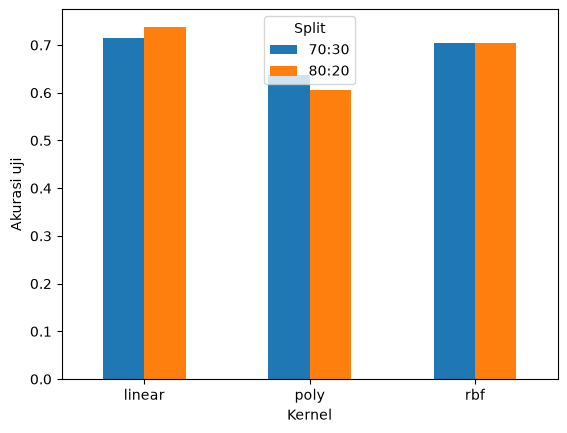

In [3]:
tabel_svm.pivot(index='Kernel',columns='Split',values='Akurasi Test').plot.bar(rot=0)
plt.ylabel('Akurasi uji')
plt.show()

In [4]:
# Tugas 2 - Teks pengganti histogram citra
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
data = pd.read_csv('../../dataset_pbl/reviews.csv')
data = data[data['rating'].isin([1,5])].head(1000).copy()
data['text'] = data['text'].fillna('').str.split().str.join(' ').str.lower()
y = data['rating'].map({1:0,5:1}).to_numpy()
text_train, text_test, y_train, y_test = train_test_split(data['text'],y,test_size=0.2,random_state=42,stratify=y)

In [5]:
# Frekuensi kata dan SVM RBF
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer(max_features=64)
train = vectorizer.fit_transform(text_train)
test = vectorizer.transform(text_test)
parameter = {'C':[0.1,1,10,100],'gamma':['scale',0.001,0.01,0.1,1]}
pencarian = GridSearchCV(SVC(kernel='rbf'),parameter,cv=5,n_jobs=1)
pencarian.fit(train,y_train)
print(pencarian.best_params_)
print('Akurasi validasi:',pencarian.best_score_)

{'C': 10, 'gamma': 1}
Akurasi validasi: 0.9487500000000001


In [6]:
# Evaluasi pada data uji
model_terbaik = pencarian.best_estimator_
pred = model_terbaik.predict(test)
print('Akurasi uji:',accuracy_score(y_test,pred))
print(classification_report(y_test,pred,zero_division=0))

Akurasi uji: 0.95
              precision    recall  f1-score   support

           0       1.00      0.09      0.17        11
           1       0.95      1.00      0.97       189

    accuracy                           0.95       200
   macro avg       0.97      0.55      0.57       200
weighted avg       0.95      0.95      0.93       200

